# Reducción de dimensionalidad de una imagen con una RBM

Una RBM necesita **muchos ejemplos**; entrenarla con una sola imagen aplanada como una única muestra (como hacía la versión anterior de este notebook) solo la hace memorizar. Aquí la imagen se divide en **parches de 8×8** (64 valores) que se solapan: cada parche es un ejemplo. La RBM aprende a describir cada parche con menos de 64 unidades ocultas y la imagen se reconstruye promediando los parches.

Es un experimento de compresión de **esa** imagen, así que se evalúa sobre los mismos datos con los que se entrena.

(160, 200)


(np.float64(-0.5), np.float64(199.5), np.float64(159.5), np.float64(-0.5))

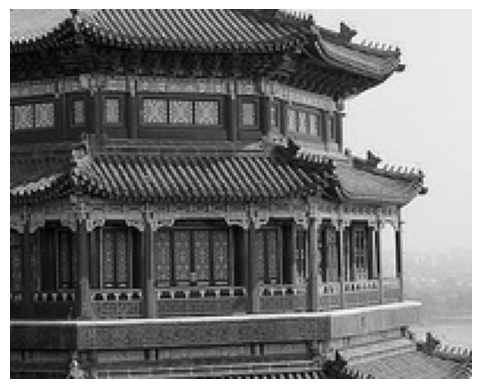

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_sample_image

from RBM import RBM

# Imagen de ejemplo incluida en scikit-learn, en escala de grises con valores en [0, 1]
image = load_sample_image('china.jpg').astype(float).mean(axis=2) / 255.0
image = image[100:260, 150:350]
print(image.shape)
plt.imshow(image, cmap='gray'); plt.axis('off')

## Parches

In [2]:
P, STRIDE = 8, 2

def extractPatches(image):
    rows = range(0, image.shape[0] - P + 1, STRIDE)
    cols = range(0, image.shape[1] - P + 1, STRIDE)
    return np.array([image[r:r + P, c:c + P].ravel() for r in rows for c in cols])

def rebuild(patches, shape):
    """Recompone la imagen promediando los parches donde se solapan."""
    out, count, k = np.zeros(shape), np.zeros(shape), 0
    for r in range(0, shape[0] - P + 1, STRIDE):
        for c in range(0, shape[1] - P + 1, STRIDE):
            out[r:r + P, c:c + P] += patches[k].reshape(P, P)
            count[r:r + P, c:c + P] += 1
            k += 1
    return out / np.maximum(count, 1)

patches = extractPatches(image)
print(f'{len(patches)} parches de {P * P} valores')

7469 parches de 64 valores


## Entrenamiento con distintos tamaños de capa oculta

Reducir los 64 valores de cada parche a 32, 16 u 8 unidades. La referencia es describir cada parche con el parche medio.

In [3]:
baseline = np.mean((patches - patches.mean(axis=0)) ** 2)
results = {}
for hidden in (32, 16, 8):
    rbm = RBM(P * P, hidden, seed=0)
    rbm.train(patches, lr=0.05, epochs=60, batch_size=64)
    results[hidden] = rebuild(rbm.reconstruct(patches), image.shape)
    print(f'{hidden:>2} unidades ocultas ({hidden / (P * P):.0%} de los 64 valores): '
          f'MSE de la imagen = {np.mean((results[hidden] - image) ** 2):.5f}')
print(f'Referencia (parche medio) en los parches: {baseline:.5f}')

32 unidades ocultas (50% de los 64 valores): MSE de la imagen = 0.01291


16 unidades ocultas (25% de los 64 valores): MSE de la imagen = 0.01466


 8 unidades ocultas (12% de los 64 valores): MSE de la imagen = 0.01636
Referencia (parche medio) en los parches: 0.07197


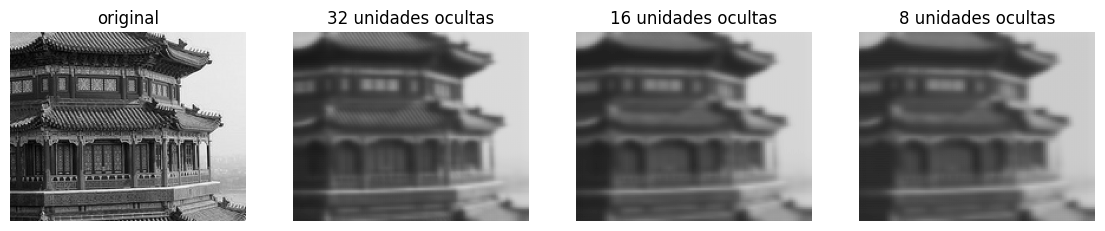

In [4]:
fig, axes = plt.subplots(1, 4, figsize=(14, 3.5))
axes[0].imshow(image, cmap='gray', vmin=0, vmax=1); axes[0].set_title('original')
for ax, hidden in zip(axes[1:], results):
    ax.imshow(results[hidden], cmap='gray', vmin=0, vmax=1); ax.set_title(f'{hidden} unidades ocultas')
for ax in axes:
    ax.axis('off')
plt.savefig('simple_image_output.png', dpi=110, bbox_inches='tight')

## Interpretación

Las reconstrucciones conservan la estructura general de la imagen pero **pierden el detalle fino** (se ven desenfocadas), y cuanto menos unidades ocultas más se pierde. El error baja con respecto a la referencia, que es lo que se espera de una reducción de dimensionalidad con pérdida, pero una RBM de una sola capa no compite con un códec de imagen.